# HCWF blending demo: India

A **blend** turns the onset climatology and the onset dates of the forecast models into probabilities that the onset falls in week 1, 2, 3, 4 or later after an issue date. This notebook trains one (cross-validated against climatology baselines), then applies it to a live 2025 forecast.

Steps: 1 setup, 2 blend config and `hcwf.check`, 3 train, 4 evaluation, 5 live forecast, 6 what else.
Models: AIFS_v2 and GraphCast (deterministic) and the 26-member AIFS_ENS_v2. Training years 2012-2023, 2024 held out. Runtime: about 1 minute on a many-core machine.

CLI equivalents: `hcwf-run -p blend.yaml` trains, `hcwf-run forecast trained.blend --forecast MODEL=PATH` applies.

## 1. Setup
One variable (`DATA`) points at the data.

In [1]:
%matplotlib inline
import os
from pathlib import Path

REGION = "india"

# ONE place that says where the data are: set HCWF_DEMO_DATA, or keep the repo's data/ folder
# (found by looking upward from the folder this notebook runs in). It must hold <region>/obs.zarr
# and <region>/models/<MODEL>.zarr.
DATA = Path(os.environ.get("HCWF_DEMO_DATA")
            or next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / REGION).is_dir())).expanduser()
OBS = DATA / REGION / "obs.zarr"
MODELS = DATA / REGION / "models"
print("data root:", DATA)

import copy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import hcwf
from hcwf.api import forecast
from hcwf.blend import TrainedBlend

plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (9, 3.5)})

data root: ../../data


The blend reads the **zarr stores directly**, as the benchmark does: observations and each model's forecasts are one store holding every year, and the live forecast below is read from the same stores. The domain is central and north India (15-27 N, 72-88 E), set with `units.box` in the config to keep the run short.

## 2. The blend config
The same dict as a benchmark, plus a `blend:` section (a config with `blend:` trains instead of benchmarking):

* `observations`, `models`: the zarr stores (`path`); a folder of yearly files or a `paths` list works the same.
* `evaluation`: the years of the issue dates (2012-2024).
* `blend.years`: `training` (fitted), `cv_holdout` (scored by **leave-one-year-out** cross-validation), `true_holdout` (scored, never fitted).
* `blend.formulas`: the recipe, a formula over features: `prob_clim_qx` (the climatology's probability) plus one term per model. `moron_robertson_mok` has a named rainfall threshold (`wet_spell_amount`), so each model also enters through `diff_<model>_qx`: its forecast 5-day rain minus that threshold.
* `blend.models`: per model, the lead days read (1-40) and optional rain predictors.
* Units are the grid cells of the stores inside `units.box` (the default for a blend is all cells). Onset definition and day boundary come from the region.

In [2]:
cfg = {
    "project_name": "India blend demo",
    "region": REGION,
    "observations": {"path": str(OBS)},
    "models": [
        {"name": "aifs", "path": str(MODELS / "AIFS_v2.zarr"), "lead_label": "end"},
        {"name": "graphcast", "path": str(MODELS / "graphcast.zarr"), "lead_label": "end"},
        {"name": "aifs_ens", "path": str(MODELS / "AIFS_ENS_v2.zarr"), "lead_label": "end"},
    ],
    "units": {"mode": "cells", "box": {"lat_min": 15, "lat_max": 27, "lon_min": 72, "lon_max": 88}},
    "evaluation": {"start_date": [2012, 5, 1], "end_date": [2024, 8, 31]},
    "blend": {
        "years": {"training": "2012:2023", "cv_holdout": "2012:2023", "true_holdout": 2024},
        "formulas": {"blended_model": "outcome ~ prob_clim_qx + diff_aifs_qx + diff_graphcast_qx + diff_aifs_ens_qx"},
        "models": {
            "aifs": {"lead_days": [1, 40], "rain_predictors": [{"agg": "diff"}]},
            "graphcast": {"lead_days": [1, 40], "rain_predictors": [{"agg": "diff"}]},
            "aifs_ens": {"lead_days": [1, 40], "rain_predictors": [{"agg": "diff"}]},
        },
    },
}

`hcwf.check` plans the blend without training: its `== Blend ==` block lists outcomes, years, formulas, the cutoff, and the artifact folder.

In [3]:
plan = hcwf.check(cfg)
print("ok:", plan.ok, "| errors:", plan.errors)
text = plan.text()
for section in text.split("\n== "):
    if section.startswith(("Settings", "Blend")):
        for line in ("== " + section).splitlines()[:22]:
            print(line[:170])

ok: True | errors: []
== Settings ==
config file     : None
region          : india  [run config]
first date      : (2012, 5, 1)  [run config]
last date       : (2024, 8, 31)  [run config]
init weekdays   : (0, 3)  [default]
climatology from: 1991  [region default]
climatology to  : 2020  [region default]
lead windows    : ((1, 15), (16, 30))  [default]
tolerances (days): (3, 5)  [default]
max forecast day: 30  [default]
day bins        : ((1, 5), (6, 10), (11, 15), (16, 20), (21, 25), (26, 30))  [default]
ensemble        : False  [default]
members         : All  [default]
reference       : climatology  [default]
climatology_cv  : leave_one_year_out  [default]
ensemble onset share: 0.5  [default]
models          : aifs, graphcast, aifs_ens
Onset definition : moron_robertson_mok v2 (draft)  [region default (india)]
Season           : main  [the definition's only season]
Threshold years  : 1991-2020  [region default (india)]
Day boundary     : 03 UTC, labelled by end  [region default (in

## 3. Train
`hcwf.run` on a blend config builds the weekly features from observed and forecast onsets, cross-validates the formula and the baselines, fits the operational model on all training years and (with `write=True`) writes the blend folder.

In [4]:
trained = hcwf.run(cfg, write=True, overwrite=True, quiet=True)
print("run folder:", trained.folder)
print(type(trained.blend).__name__, "| cross-validated formulas:", list(trained.blend.evaluation.formulas))

run folder: runs/india_moron-robertson-mok_2012-2024_1e1e
TrainingResult | cross-validated formulas: ['blended_model']


## 4. Evaluation
`trained.blend.evaluation` holds the score tables as DataFrames; each is also a CSV in `blend/`. Skill is relative to the climatology baselines (positive = better); `rps` is the ranked probability score over the five week bins.

In [5]:
evaluation = trained.blend.evaluation
pooled = evaluation.pooled.set_index("model")
display(pooled[["brier", "rps", "auc", "brier_skill", "rps_skill"]].round(3))

,brier,rps,auc,brier_skill,rps_skill
model,,,,,
blended_model,0.618,0.506,0.807,0.204,0.403
unc_clim_raw,0.777,0.848,0.689,0.000,0.000
clim_raw,0.696,0.591,0.750,0.104,0.303
aifs_fixed_cutoff_raw,0.994,0.759,0.689,-0.280,0.105
aifs_calibrated_fixed_cutoff,0.658,0.548,0.769,0.153,0.354
graphcast_fixed_cutoff_raw,1.006,0.805,0.686,-0.295,0.051
graphcast_calibrated_fixed_cutoff,0.665,0.559,0.765,0.144,0.341
aifs_ens_fixed_cutoff_raw,0.645,0.532,0.808,0.169,0.373
aifs_ens_calibrated_fixed_cutoff,0.613,0.503,0.809,0.210,0.407


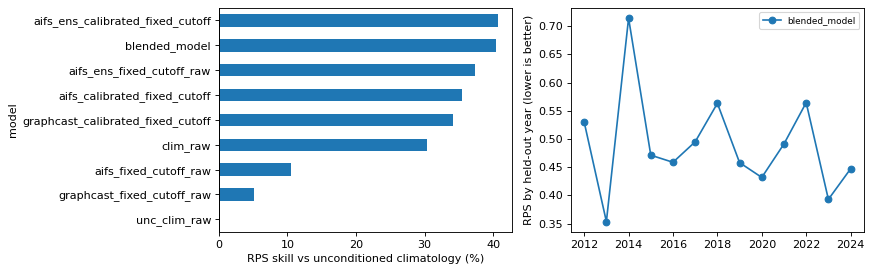

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
(pooled["rps_skill"] * 100).sort_values().plot.barh(ax=axes[0])
axes[0].axvline(0, color="k", lw=0.8); axes[0].set_xlabel("RPS skill vs unconditioned climatology (%)")
yearly = evaluation.yearly
for model, part in yearly.groupby("model"):   # the models with cross-validated predictions
    axes[1].plot(part["year"], part["rps"], "o-", label=model)
axes[1].set_ylabel("RPS by held-out year (lower is better)"); axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

The files of the `blend/` folder (names follow the former `onset_blending` contract). `<tag>` encodes the cutoff mode and years.

In [7]:
blend_dir = trained.folder / "blend"
for path in sorted(blend_dir.iterdir()):
    print(f"{path.stat().st_size / 1e3:9.0f} kB  {path.name}")
display(pd.read_csv(next(blend_dir.glob("summary_models_<tag>.csv".replace("<tag>", "fixed_cutoff_*")))).head(3).round(3))

       29 kB  coefs_blended_model_global_fixed_cutoff_2012_2024.nc
    21220 kB  cv_preds_blended_model_global_fixed_cutoff_2012_2024.nc
        1 kB  formula_sample_support_fixed_cutoff_2012_2024.json
     2593 kB  summary_models_fixed_cutoff_2012_2024.csv
        3 kB  summary_models_pooled_fixed_cutoff_2012_2024.csv
      730 kB  trained.blend
        1 kB  yearly_metrics_global_fixed_cutoff_2012_2024.csv


,id,brier,rps,auc,n,lat,lon,pietra,brier_week1,brier_week2,brier_week3,brier_week4,brier_later,auc_week1,auc_week2,auc_week3,auc_week4,auc_later,model,cv_method
0,15.25_73.75,0.541,0.352,0.887,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,blended_model,global
1,15.25_74,0.540,0.344,0.896,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,blended_model,global
2,15.25_74.25,0.552,0.352,0.885,39,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,blended_model,global


`trained.blend` (a `TrainingResult`) has the evaluation, and `trained.blend.model` is the operational model. The file `trained.blend` is the self-contained product: run config, definition, recipe, models, observed onsets, units, thresholds and reference. It loads back as a `TrainedBlend`.

In [8]:
blend_file = blend_dir / "trained.blend"
loaded = TrainedBlend.load(blend_file)
print(type(loaded).__name__, "| models:", [m for m in loaded.recipe.model_names], "| definition:", loaded.definition_text[:90], "...")

TrainedBlend | models: ['aifs', 'graphcast', 'aifs_ens'] | definition: id: moron_robertson_mok
version: 2
title: Moron and Robertson onset, searched from the med ...


## 5. Live forecast
Apply the trained blend to the forecasts of one 2025 issue date (2025-06-05, outside the training years). `forecast` takes one source per trained model (a file, a glob or a zarr store) and, for a store holding many issues, the `issue_date`. The forecast must have the units, grid spacing and issue hour the blend was trained on; every difference is reported before anything is read.

In [9]:
ISSUE = "2025-06-05"
live = {"aifs": str(MODELS / "AIFS_v2.zarr"), "graphcast": str(MODELS / "graphcast.zarr"), "aifs_ens": str(MODELS / "AIFS_ENS_v2.zarr")}

fc = forecast(blend_file, live, issue_date=ISSUE, quiet=True)
print("issue dates:", fc.issue_dates)
fc.weekly

issue dates: [datetime.date(2025, 6, 5)]


<xarray.Dataset> Size: 291kB
Dimensions:          (time: 1, id: 2600)
Coordinates:
  * time             (time) datetime64[s] 8B 2025-06-05
  * id               (id) object 21kB '15.25_73.75' '15.25_74' ... '27_88'
Data variables: (12/13)
    cv_week1         (time, id) float64 21kB 0.9616 0.8928 ... 0.2668 0.1357
    cv_week2         (time, id) float64 21kB 0.03835 0.1069 ... 0.28 0.2807
    cv_week3         (time, id) float64 21kB 1.451e-05 4.377e-05 ... 0.4963
    cv_week4         (time, id) float64 21kB 6.141e-06 2.047e-05 ... 0.07394
    cv_later         (time, id) float64 21kB 5.938e-05 0.0002098 ... 0.01343
    clim_week1       (time, id) float64 21kB 0.6638 0.6147 ... 0.3619 0.5365
    ...               ...
    clim_week3       (time, id) float64 21kB 0.02527 0.05608 ... 0.198 0.1692
    clim_week4       (time, id) float64 21kB 0.0001706 0.005976 ... 0.0443
    clim_later       (time, id) float64 21kB 0.02866 0.0273 ... 0.05525 0.002626
    lat              (id) float64 21kB 15.25 15.25 15.25 ... 27.0 27.0 27.0
    lon              (id) float64 21kB 73.75 74.0 74.25 74.5 ... 85.25 85.5 88.0
    onset_threshold  (id) float64 21kB 103.6 113.5 115.5 ... 39.3 38.38 71.44

`fc.weekly_table` is the contract table (one row per unit and issue: the blend's `cv_week1..4`, `cv_later` and the climatology's `clim_*`). The map shows the blend's probability of onset in each week, and its change against climatology.

In [10]:
display(fc.weekly_table.head(3).round(3))

,id,time,onset_threshold,lat,lon,cv_week1,cv_week2,cv_week3,cv_week4,cv_later,clim_week1,clim_week2,clim_week3,clim_week4,clim_later
0,15.25_73.75,2025-06-05,103.649,15.25,73.75,0.962,0.038,0.0,0.0,0.0,0.664,0.282,0.025,0.000,0.029
1,15.25_74,2025-06-05,113.532,15.25,74.00,0.893,0.107,0.0,0.0,0.0,0.615,0.296,0.056,0.006,0.027
2,15.25_74.25,2025-06-05,115.547,15.25,74.25,0.679,0.320,0.0,0.0,0.0,0.342,0.304,0.197,0.087,0.069


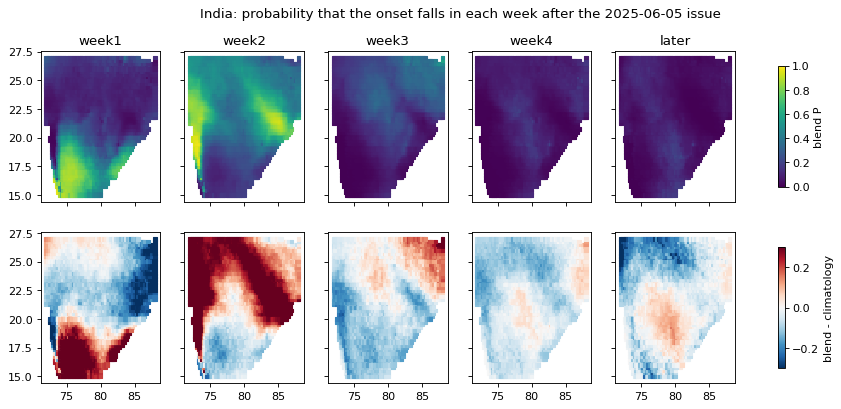

In [11]:
weeks = ["cv_week1", "cv_week2", "cv_week3", "cv_week4", "cv_later"]
data = fc.weekly.isel(time=0)
fig, axes = plt.subplots(2, 5, figsize=(14, 5.4), sharex=True, sharey=True)
for col, name in enumerate(weeks):
    blend_p = data[name]
    for row, (values, cmap, vmin, vmax, label) in enumerate([
            (blend_p, "viridis", 0, 1, "blend P"),
            (blend_p - data[name.replace("cv_", "clim_")], "RdBu_r", -0.3, 0.3, "blend - climatology")]):
        ax = axes[row, col]
        points = ax.scatter(data["lon"], data["lat"], c=values, s=9, marker="s", cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(name.replace("cv_", "") if row == 0 else "")
        if col == len(weeks) - 1:
            fig.colorbar(points, ax=axes[row], shrink=0.8, label=label)
fig.suptitle(f"India: probability that the onset falls in each week after the {ISSUE} issue")
plt.show()

## 6. What else
**Save and share.** `forecast(..., write=True)` (or the CLI) writes `blended_forecast_probabilities.csv`, the contract file; `netcdf=True` adds a NetCDF twin. A `trained.blend` can be copied anywhere and loaded with `TrainedBlend.load`; `forecast` takes the loaded blend as well as the file (`loaded.forecast({...})` is the method behind it). `quiet=True` leaves out the notes of the reading.

In [12]:
out = forecast(blend_file, live, issue_date=ISSUE, write=True, netcdf=True, quiet=True,
               output=trained.folder / "forecasts" / ISSUE)
print("written to", out.folder)
for path in sorted(out.folder.iterdir()):
    print(f"{path.stat().st_size / 1e3:9.0f} kB  {path.name}")
same = forecast(loaded, live, issue_date=ISSUE, quiet=True)   # a loaded TrainedBlend works too
print("same probabilities from TrainedBlend.forecast:", np.allclose(same.weekly["cv_week1"], fc.weekly["cv_week1"]))

written to runs/india_moron-robertson-mok_2012-2024_1e1e/forecasts/2025-06-05
      645 kB  blended_forecast_probabilities.csv
      459 kB  blended_forecast_probabilities.nc


same probabilities from TrainedBlend.forecast: True


The same from the shell (several `--forecast MODEL=PATH`, one per trained model; `-o` is a new or empty folder):

```bash
hcwf-run -p blend.yaml                                   # train (the config above, as YAML)
hcwf-run forecast runs/<run>/blend/trained.blend \
    --forecast aifs=data/india/models/AIFS_v2.zarr --forecast graphcast=data/india/models/graphcast.zarr \
    --forecast aifs_ens=data/india/models/AIFS_ENS_v2.zarr \
    --issue-date 2025-06-05 --netcdf -o forecasts/2025-06-09
```
Blend keys, units on polygons and several blends in one go: `docs/blending.md`.